In [1]:
import autograd.numpy as np
import pymanopt
from pymanopt.manifolds import sphere
from pymanopt.manifolds import positive_definite
from pymanopt.tools import diagnostics

## Quadratic function over sphere: 

In [4]:
#Define the manifold via pymanopt
n = 7
M = np.random.randn(n, n)
A = M + M.T #A is a symmetric matrix

manifold = sphere.Sphere(n)

In [7]:
#Define cost function 
@pymanopt.function.autograd(manifold)
def cost(point):
    return point.T @ A @ point 
def grad_candidate(A, X):
    return 2 * A @ X - 2 * X * (X.T @ A @ X)

problem = pymanopt.Problem(manifold, cost)

Directional derivative check. The slope of the continuous line should match that of the dashed (reference) line over at least a few orders of magnitude for h.


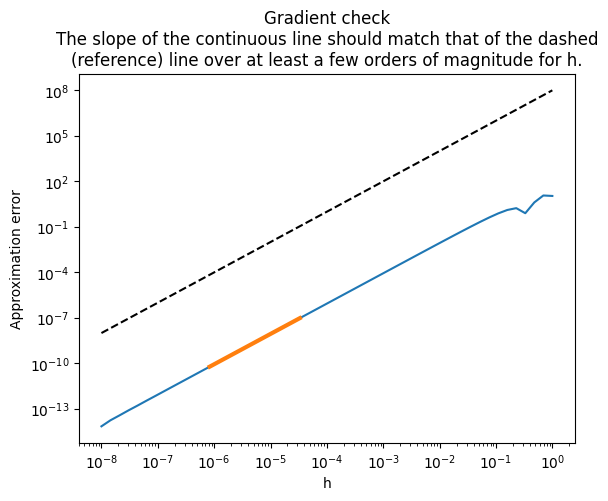

The residual should be close to 0: 3.72093e-15.
If it is far from 0, then the gradient is not in the tangent space.


In [9]:
#Check the gradient defined above
x = problem.manifold.random_point()
d = grad_candidate(A, x)
diagnostics.check_gradient(problem, x, d)

In [11]:
for i in range(5):
    X0 = problem.manifold.random_point()
    optimizer = pymanopt.optimizers.SteepestDescent(verbosity=0)
    result = optimizer.run(problem, initial_point=X0)
    print(f"Run {i+1}: {result.point}, {result.cost} ")

Run 1: [ 0.25809215 -0.24663087  0.38004895  0.49549965 -0.32037332 -0.05604799
  0.61386001], -6.461203166456088 
Run 2: [ 0.25809221 -0.24663099  0.38004895  0.49549963 -0.32037329 -0.05604799
  0.61385996], -6.461203166456072 
Run 3: [-0.25809214  0.24663087 -0.38004895 -0.49549964  0.32037332  0.05604799
 -0.61386002], -6.461203166456078 
Run 4: [ 0.25809217 -0.24663092  0.38004894  0.49549963 -0.32037331 -0.05604798
  0.61386   ], -6.461203166456079 
Run 5: [ 0.25809219 -0.24663094  0.38004896  0.49549964 -0.3203733  -0.05604799
  0.61385998], -6.461203166456094 


### Test for multi-start random points, we showed that our problem admits 2 global minimum $x$ and $-x$. Theoretically, the minimum corresponds to the smallest eigenvalue of $A$ and the $x$ and $-x$ are unit-norm eigenvectors of this eigenvalue. 

In [12]:
eigenvalues, eigenvectors = np.linalg.eigh(A)
print(eigenvalues)
eigenvectors

[-6.46120317 -4.31541875 -3.28414154  0.19909448  0.64835392  5.58035818
  6.11011029]


array([[-0.25809218,  0.41925803,  0.75833125,  0.27954936, -0.15067385,
         0.00091221,  0.28582086],
       [ 0.2466309 , -0.81967291,  0.37856787,  0.07833132, -0.04000274,
        -0.10837647,  0.32328688],
       [-0.38004896, -0.01000971, -0.31277005, -0.21807522, -0.50038842,
        -0.50495466,  0.45245211],
       [-0.49549965, -0.08626608, -0.06494767, -0.10361481,  0.77536901,
         0.01514483,  0.36146586],
       [ 0.32037331,  0.19551896,  0.30812678, -0.8593304 ,  0.10218946,
        -0.09465175,  0.07962914],
       [ 0.056048  ,  0.03830645,  0.14323243,  0.16947045,  0.27848934,
        -0.84089761, -0.40185864],
       [-0.61385998, -0.32422514,  0.25321758, -0.30042397, -0.19003291,
         0.13029729, -0.55730636]])